# Product Return Prediction — Complete Capstone Notebook

This notebook implements the 8 exercises in `Product_Return_Prediction_Student_Exercises.pdf` and builds a leakage-aware return prediction model.

**Target:** `returned` (0 = not returned, 1 = returned). The stated business goal is prediction **before shipping**, so post-purchase fields are excluded from the final leakage-safe model.

**Dataset:** Place `returns_dataset.csv` inside a `dataset/` folder next to this notebook. If it is not found, this notebook creates a clearly labelled synthetic demonstration dataset so that the code can run end-to-end. Synthetic results will not reproduce the exercise PDF's reference numbers.

## 1. Imports and setup

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             precision_recall_curve, roc_auc_score)
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
Path("dataset").mkdir(exist_ok=True)
Path("artifacts").mkdir(exist_ok=True)
print("Setup complete")

Setup complete


## 2. Load data (or create a demo dataset if the CSV is absent)

In [2]:
DATA_FILE = Path("dataset/returns_dataset.csv")

if DATA_FILE.exists():
    df = pd.read_csv(DATA_FILE)
    print(f"Loaded real exercise CSV: {DATA_FILE}")
else:
    print("WARNING: dataset/returns_dataset.csv not found. Creating synthetic demo data.")
    print("Replace this demo data with the provided CSV for meaningful exercise results.")
    n = 12000
    rng = np.random.default_rng(RANDOM_STATE)
    brands = [f"Brand_{i}" for i in range(1, 31)]
    brand = rng.choice(brands, n)
    payment = rng.choice(["COD", "UPI", "Credit Card", "Debit Card", "Wallet"], n,
                         p=[.25, .25, .22, .18, .10])
    fragile = rng.binomial(1, .25, n)
    delayed = rng.binomial(1, .20, n)
    price = np.clip(rng.lognormal(np.log(600), 1.0, n), 50, 65000)
    support = rng.poisson(0.5, n)
    chat = rng.poisson(0.7, n)
    # Synthetic probability includes several realistic associations.
    logits = (-1.35 + 1.15*fragile + 1.05*delayed + .95*(payment == "COD")
              - .35*(payment == "UPI") + .25*(support + chat > 2)
              + .15*rng.normal(size=n))
    prob = 1/(1+np.exp(-logits))
    returned = rng.binomial(1, prob)
    df = pd.DataFrame({
        "order_id": np.arange(1, n+1),
        "product_category": rng.choice(["Electronics", "Fashion", "Home", "Beauty", "Sports"], n),
        "sub_category": rng.choice(["A", "B", "C", "D", "E"], n),
        "brand": brand,
        "fulfillment_type": rng.choice(["Marketplace Fulfilled", "Seller Fulfilled", "marketplace fulfilled "], n),
        "payment_method": payment,
        "product_price": price,
        "discount_percent": rng.uniform(0, 50, n),
        "product_rating": rng.normal(3.8, .7, n).clip(1, 5),
        "seller_rating": rng.normal(4.0, .5, n).clip(1, 5),
        "review_count": rng.poisson(25, n),
        "shipping_distance_km": rng.uniform(1, 2000, n),
        "product_page_views": rng.poisson(30, n),
        "defect_rate": rng.uniform(0, .25, n),
        "quantity": rng.integers(1, 6, n),
        "fragile_item": fragile,
        "delayed_delivery": delayed,
        "warranty_available": rng.binomial(1, .6, n),
        "wishlist_before_purchase": rng.binomial(1, .3, n),
        "customer_support_calls": support,
        "chat_interactions": chat,
        "product_return_rate": np.clip(.25 + .12*rng.normal(size=n), 0, 1),
        "brand_return_rate": np.clip(.25 + .12*rng.normal(size=n), 0, 1),
        "avg_return_rate": np.clip(.25 + .05*rng.normal(size=n), 0, 1),
        "returned": returned
    })
    # Inject a few missing values and a price outlier to demonstrate data-quality checks.
    for col, count in [("product_rating", 240), ("seller_rating", 180),
                       ("review_count", 120), ("shipping_distance_km", 120)]:
        idx = rng.choice(df.index, count, replace=False)
        df.loc[idx, col] = np.nan
    df.loc[df.index[0], "product_price"] = 64879

print("Shape:", df.shape)
display(df.head())
assert "returned" in df.columns, "CSV must contain the target column 'returned'."
print("Target values:", sorted(df["returned"].dropna().unique()))

Loaded real exercise CSV: dataset\returns_dataset.csv
Shape: (12000, 26)


,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,0.172,0.173,0.219,0.116,4.1,0.128,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,0.168,0.125,0.155,0.031,4.2,0.171,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,0.045,0.125,0.103,0.057,4.1,0.186,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,ORD100003,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,0.066,0.119,0.085,0.064,3.9,0.133,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,ORD100004,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,0.183,0.075,0.177,0.076,4.6,0.172,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0


Target values: [np.int64(0), np.int64(1)]


## 3. Initial EDA

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  12000 non-null  str    
 1   product_category          12000 non-null  str    
 2   sub_category              12000 non-null  str    
 3   brand                     12000 non-null  str    
 4   product_price             12000 non-null  float64
 5   discount_percent          12000 non-null  float64
 6   product_rating            11760 non-null  float64
 7   review_count              11880 non-null  float64
 8   fragile_item              12000 non-null  int64  
 9   warranty_available        12000 non-null  int64  
 10  product_return_rate       12000 non-null  float64
 11  category_return_rate      12000 non-null  float64
 12  brand_return_rate         12000 non-null  float64
 13  defect_rate               12000 non-null  float64
 14  seller_rating    

None


Target counts:


,orders
returned,
0,8355
1,3645



Target percentages:


,percent
returned,
0,69.62
1,30.38


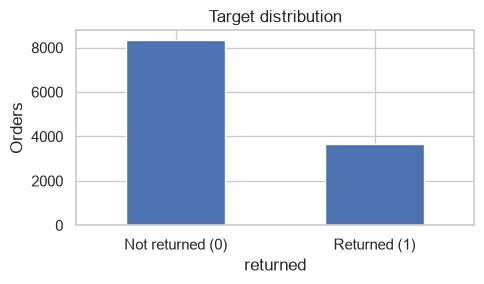

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,12000,12000,ORD100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,12000,7,Fashion,3413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sub_category,12000,23,Mobiles,904,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,12000,30,Brand_26,442,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_price,12000.0,NaN,NaN,NaN,964.063342,1678.771489,19.51,328.235,597.47,1105.395,64878.67
discount_percent,12000.0,NaN,NaN,NaN,33.567167,19.378304,0.0,16.8,33.5,50.4,67.0
product_rating,11760.0,NaN,NaN,NaN,3.886505,0.635664,1.6,3.5,3.9,4.3,5.0
review_count,11880.0,NaN,NaN,NaN,69.437205,18.446294,24.0,54.0,69.0,85.0,116.0
fragile_item,12000.0,NaN,NaN,NaN,0.197083,0.397812,0.0,0.0,0.0,0.0,1.0
warranty_available,12000.0,NaN,NaN,NaN,0.4465,0.49715,0.0,0.0,0.0,1.0,1.0


Missing values by column:


,missing_count
product_rating,240
review_count,120
seller_rating,180
shipping_distance_km,120


In [3]:
display(df.info())
print("\nTarget counts:")
display(df["returned"].value_counts(dropna=False).to_frame("orders"))
print("\nTarget percentages:")
display((df["returned"].value_counts(normalize=True)*100).round(2).to_frame("percent"))
ax = df["returned"].value_counts().sort_index().plot(kind="bar", figsize=(5,3))
ax.set_xticklabels(["Not returned (0)", "Returned (1)"], rotation=0)
ax.set_ylabel("Orders"); ax.set_title("Target distribution"); plt.tight_layout(); plt.show()

display(df.describe(include="all").T)
print("Missing values by column:")
display(df.isna().sum().loc[lambda x: x.gt(0)].to_frame("missing_count"))

## Exercise 1 — The Bug Hunt: identify data-quality problems

In [4]:
quality_issues = []
for col, count in df.isna().sum().items():
    if count > 0:
        quality_issues.append({"Issue": f"Missing values in {col}",
                               "Evidence": f"{count} rows ({count/len(df):.1%})",
                               "Possible fix": "Impute using training-set statistics; investigate why missing"})

if "fulfillment_type" in df.columns:
    raw_counts = df["fulfillment_type"].astype("string").value_counts(dropna=False)
    normalized_counts = df["fulfillment_type"].astype("string").str.strip().str.title().value_counts(dropna=False)
    print("Original fulfillment_type values:")
    display(raw_counts.to_frame("count"))
    print("Counts after strip + title normalization:")
    display(normalized_counts.to_frame("count"))
    quality_issues.append({"Issue": "Inconsistent fulfillment_type casing/whitespace",
                           "Evidence": "Compare original and normalized value counts above",
                           "Possible fix": "Strip whitespace and standardize capitalization"})

print("Duplicate rows:", int(df.duplicated().sum()))
quality_issues.append({"Issue": "Potential duplicate rows",
                       "Evidence": f"{int(df.duplicated().sum())} exact duplicates",
                       "Possible fix": "Investigate, then remove true duplicate records"})
if "product_price" in df.columns:
    price_skew = df["product_price"].skew()
    quality_issues.append({"Issue": "Potentially right-skewed product_price",
                           "Evidence": f"skewness={price_skew:.3f}; median={df['product_price'].median():.2f}; max={df['product_price'].max():.2f}",
                           "Possible fix": "Check extreme values; consider log1p if justified"})
display(pd.DataFrame(quality_issues))

Original fulfillment_type values:


,count
fulfillment_type,
Marketplace Fulfilled,7193
Seller Fulfilled,4747
marketplace fulfilled,60


Counts after strip + title normalization:


,count
fulfillment_type,
Marketplace Fulfilled,7253
Seller Fulfilled,4747


Duplicate rows: 0


,Issue,Evidence,Possible fix
0,Missing values in product_rating,240 rows (2.0%),Impute using training-set statistics; investig...
1,Missing values in review_count,120 rows (1.0%),Impute using training-set statistics; investig...
2,Missing values in seller_rating,180 rows (1.5%),Impute using training-set statistics; investig...
3,Missing values in shipping_distance_km,120 rows (1.0%),Impute using training-set statistics; investig...
4,Inconsistent fulfillment_type casing/whitespace,Compare original and normalized value counts a...,Strip whitespace and standardize capitalization
5,Potential duplicate rows,0 exact duplicates,"Investigate, then remove true duplicate records"
6,Potentially right-skewed product_price,skewness=16.165; median=597.47; max=64878.67,Check extreme values; consider log1p if justified


## Exercise 2 — Guess-then-Check: compare intuition with evidence

In [5]:
# Write your three guesses here before interpreting the tables.
my_three_guesses = ["product_price", "discount_percent", "payment_method"]
print("My initial guesses:", my_three_guesses)

numeric = df.select_dtypes(include=np.number)
if "returned" in numeric.columns:
    numeric_corr = numeric.corr(numeric_only=True)["returned"].drop("returned", errors="ignore")
    numeric_corr = numeric_corr.reindex(numeric_corr.abs().sort_values(ascending=False).index)
    print("Numeric correlations ranked by absolute magnitude:")
    display(numeric_corr.to_frame("correlation_with_returned").round(4))

categorical_cols = [c for c in ["fragile_item", "delayed_delivery", "payment_method",
                                "product_category", "brand", "fulfillment_type"] if c in df.columns]
for col in categorical_cols:
    print(f"Return rate by {col}")
    display(df.groupby(col, dropna=False)["returned"].agg(return_rate="mean", orders="size")
            .sort_values("return_rate", ascending=False).round(4))

My initial guesses: ['product_price', 'discount_percent', 'payment_method']
Numeric correlations ranked by absolute magnitude:


,correlation_with_returned
brand_return_rate,0.3368
product_return_rate,0.3130
fragile_item,0.2581
delayed_delivery,0.2294
warranty_available,-0.2138
shipping_distance_km,0.1619
product_rating,-0.1105
customer_support_calls,0.0935
chat_interactions,0.0923
defect_rate,0.0737


Return rate by fragile_item


,return_rate,orders
fragile_item,,
1,0.5433,2365
0,0.2449,9635


Return rate by delayed_delivery


...

,return_rate,orders
product_category,,
Books,0.3143,910
Sports,0.3111,1202
Beauty,0.3076,1453
Electronics,0.3045,2601
Fashion,0.2997,3413
Home,0.2990,1816
Toys,0.2975,605


Return rate by brand


,return_rate,orders
brand,,
Brand_23,0.6076,367
Brand_14,0.6074,405
Brand_4,0.5600,400
Brand_19,0.5369,406
Brand_11,0.5254,413
Brand_12,0.4758,351
Brand_3,0.4731,391
Brand_27,0.4293,375
Brand_15,0.4167,420


Return rate by fulfillment_type


,return_rate,orders
fulfillment_type,,
Seller Fulfilled,0.3059,4747
Marketplace Fulfilled,0.3029,7193
marketplace fulfilled,0.2333,60


## Exercise 3 — Should You Log-Transform It?

,skewness,minimum,maximum,decision
product_price,16.1646,19.510,64878.670,Use log1p if non-negative; verify skew and ext...
customer_support_calls,1.8130,0.000,4.000,Investigate distribution; transform only if me...
delayed_delivery,1.6391,0.000,1.000,Do not log-transform binary flag
fragile_item,1.5232,0.000,1.000,Do not log-transform binary flag
chat_interactions,1.4445,0.000,5.000,Investigate distribution; transform only if me...
defect_rate,1.4135,0.000,0.370,Investigate distribution; transform only if me...
wishlist_before_purchase,0.8856,0.000,1.000,Do not log-transform binary flag
product_rating,-0.2459,1.600,5.000,No log transform based on skew alone
warranty_available,0.2153,0.000,1.000,Do not log-transform binary flag
seller_rating,-0.1703,2.200,5.000,No log transform based on skew alone


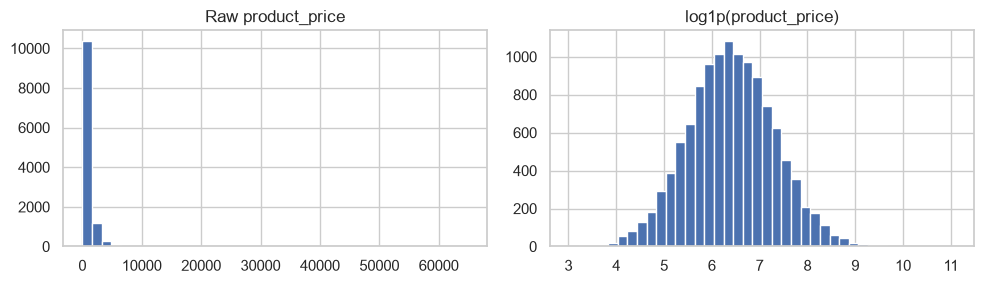

In [6]:
# Exercise 3: quantify skew for every numeric column.
numeric_cols = df.select_dtypes(include=np.number).columns.drop("returned", errors="ignore")
skew_table = pd.DataFrame({
    "skewness": df[numeric_cols].skew(numeric_only=True),
    "minimum": df[numeric_cols].min(numeric_only=True),
    "maximum": df[numeric_cols].max(numeric_only=True)
})

# Binary flags are not candidates for log transformation, even if their skew is high.
binary_cols = [
    c for c in numeric_cols
    if set(df[c].dropna().unique()).issubset({0, 1})
]
skew_table["decision"] = "No log transform based on skew alone"
skew_table.loc[skew_table["skewness"].abs() > 1, "decision"] = (
    "Investigate distribution; transform only if meaningful"
)
skew_table.loc[binary_cols, "decision"] = "Do not log-transform binary flag"
if "product_price" in skew_table.index:
    skew_table.loc["product_price", "decision"] = (
        "Use log1p if non-negative; verify skew and extreme values"
    )

display(skew_table.sort_values("skewness", key=lambda s: s.abs(), ascending=False).round(4))

if "product_price" in df.columns:
    price = df["product_price"].dropna()
    if (price >= 0).all():
        fig, axes = plt.subplots(1, 2, figsize=(10, 3))
        price.hist(bins=40, ax=axes[0])
        axes[0].set_title("Raw product_price")
        np.log1p(price).hist(bins=40, ax=axes[1])
        axes[1].set_title("log1p(product_price)")
        plt.tight_layout()
        plt.show()


## 4. Clean and prepare data

In [7]:
df_clean = df.copy()
# Standardize category formatting.
if "fulfillment_type" in df_clean.columns:
    df_clean["fulfillment_type"] = df_clean["fulfillment_type"].astype("string").str.strip().str.title()
if "brand" in df_clean.columns:
    df_clean["brand"] = df_clean["brand"].astype("string").str.strip()
# Remove exact duplicate records and rows without a target.
start_rows = len(df_clean)
df_clean = df_clean.drop_duplicates().dropna(subset=["returned"]).copy()
df_clean["returned"] = df_clean["returned"].astype(int)
if "order_id" in df_clean.columns:
    df_clean = df_clean.drop(columns=["order_id"])
print(f"Removed {start_rows-len(df_clean)} duplicate/missing-target rows. Shape: {df_clean.shape}")
print(df_clean["returned"].value_counts(normalize=True).round(3))

Removed 0 duplicate/missing-target rows. Shape: (12000, 25)
returned
0    0.696
1    0.304
Name: proportion, dtype: float64


## Exercise 4 — The Redundant-Feature Trap

In [8]:
required = {"customer_support_calls", "chat_interactions", "returned"}
if required.issubset(df_clean.columns):
    redundant = df_clean[["customer_support_calls", "chat_interactions"]].copy()
    redundant = redundant.fillna(redundant.median(numeric_only=True))
    redundant["total_support_contacts"] = redundant["customer_support_calls"] + redundant["chat_interactions"]
    # Condition number of the standardized design matrix; exact dependency remains rank deficient.
    Z_all = StandardScaler().fit_transform(redundant)
    cond_all = np.linalg.cond(Z_all)
    Z_fixed = StandardScaler().fit_transform(redundant[["total_support_contacts"]])
    cond_fixed = np.linalg.cond(Z_fixed)
    print("Condition number with all three features:", cond_all)
    print("Condition number after keeping only total_support_contacts:", cond_fixed)
    diag = LogisticRegression(max_iter=1000).fit(Z_all, df_clean.loc[redundant.index, "returned"])
    display(pd.Series(diag.coef_[0], index=redundant.columns).to_frame("coefficient"))
    print("Diagnosis: total_support_contacts is exactly the sum of the other two columns. Keep the combined feature OR both components, not all three.")
else:
    print("Required support-contact columns are not present; skip this diagnostic for this dataset.")

Condition number with all three features: 113443519310914.28
Condition number after keeping only total_support_contacts: 1.0


,coefficient
customer_support_calls,0.110087
chat_interactions,0.087794
total_support_contacts,0.137736


Diagnosis: total_support_contacts is exactly the sum of the other two columns. Keep the combined feature OR both components, not all three.


## 5. Feature engineering and prediction-time leakage audit

In [9]:
# Exercise 7: define prediction time as BEFORE shipping.
# Only use features that plausibly exist by the prediction point.
post_purchase_candidates = [
    "delayed_delivery",
    "customer_support_calls",
    "chat_interactions",
    "total_support_contacts",
]
historical_rate_candidates = [
    c for c in df_clean.columns
    if "return_rate" in c.lower() or c.lower() == "avg_return_rate"
]

leakage_rows = []
for col in historical_rate_candidates:
    leakage_rows.append({
        "feature": col,
        "decision": "EXCLUDE until point-in-time validity is verified",
        "reason": (
            "Could leak current/future outcomes unless calculated from prior orders only, "
            "excluding the current order."
        ),
    })

for col in post_purchase_candidates:
    if col in df_clean.columns:
        leakage_rows.append({
            "feature": col,
            "decision": "DROP for pre-shipment prediction",
            "reason": "May only become known after the order is placed or shipped.",
        })

for col in ["product_price", "payment_method", "product_category",
            "sub_category", "brand", "fragile_item", "warranty_available",
            "wishlist_before_purchase"]:
    if col in df_clean.columns:
        leakage_rows.append({
            "feature": col,
            "decision": "KEEP if confirmed available at order time",
            "reason": "Plausibly available at prediction time; verify with the business process.",
        })

leakage_audit = pd.DataFrame(leakage_rows).drop_duplicates(subset=["feature"])
display(leakage_audit)

# Transform price only after checking that it is non-negative and skewed.
if "product_price" in df_clean.columns and (df_clean["product_price"].dropna() >= 0).all():
    if abs(df_clean["product_price"].skew()) > 1:
        df_clean["log_price"] = np.log1p(df_clean["product_price"])
        df_clean = df_clean.drop(columns=["product_price"])

# Do NOT create total_support_contacts in the deployment feature table:
# its components may be unavailable before shipping. Exercise 4 above is diagnostic only.
support_related = [
    c for c in ["customer_support_calls", "chat_interactions", "total_support_contacts"]
    if c in df_clean.columns
]
if support_related:
    df_clean = df_clean.drop(columns=support_related)

# Exclude historical rates until their point-in-time validity is proven.
leakage_drop = [
    c for c in df_clean.columns
    if "return_rate" in c.lower() or c.lower() == "avg_return_rate"
]
leakage_drop += [c for c in post_purchase_candidates if c in df_clean.columns]
leakage_drop = list(dict.fromkeys(leakage_drop))
print("Excluded from pre-shipment model:", leakage_drop)
print("Support-related columns excluded from deployment features:", support_related)


,feature,decision,reason
0,product_return_rate,EXCLUDE until point-in-time validity is verified,Could leak current/future outcomes unless calc...
1,category_return_rate,EXCLUDE until point-in-time validity is verified,Could leak current/future outcomes unless calc...
2,brand_return_rate,EXCLUDE until point-in-time validity is verified,Could leak current/future outcomes unless calc...
3,seller_return_rate,EXCLUDE until point-in-time validity is verified,Could leak current/future outcomes unless calc...
4,delayed_delivery,DROP for pre-shipment prediction,May only become known after the order is place...
5,customer_support_calls,DROP for pre-shipment prediction,May only become known after the order is place...
6,chat_interactions,DROP for pre-shipment prediction,May only become known after the order is place...
7,product_price,KEEP if confirmed available at order time,Plausibly available at prediction time; verify...
8,payment_method,KEEP if confirmed available at order time,Plausibly available at prediction time; verify...
9,product_category,KEEP if confirmed available at order time,Plausibly available at prediction time; verify...


Excluded from pre-shipment model: ['product_return_rate', 'category_return_rate', 'brand_return_rate', 'seller_return_rate', 'delayed_delivery']
Support-related columns excluded from deployment features: ['customer_support_calls', 'chat_interactions']


## 6. Train / validation / test split

In [10]:
# Split before fitting any preprocessing. Test set remains untouched until final evaluation.
y = df_clean["returned"].astype(int)
X = df_clean.drop(columns=["returned"] + leakage_drop, errors="ignore")
X = X.drop(columns=[c for c in X.columns if X[c].isna().all()], errors="ignore")

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    stratify=y_train_full, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Train return rate:", round(y_train.mean(), 3),
      "Validation return rate:", round(y_val.mean(), 3),
      "Test return rate:", round(y_test.mean(), 3))
print("\nFinal feature list:")
print(X.columns.tolist())


Train: (7680, 17) Validation: (1920, 17) Test: (2400, 17)
Train return rate: 0.304 Validation return rate: 0.304 Test return rate: 0.304

Final feature list:
['product_category', 'sub_category', 'brand', 'discount_percent', 'product_rating', 'review_count', 'fragile_item', 'warranty_available', 'defect_rate', 'seller_rating', 'fulfillment_type', 'payment_method', 'quantity', 'shipping_distance_km', 'wishlist_before_purchase', 'product_page_views', 'log_price']


## 7. Preprocessing pipeline (fit on training data only)

In [22]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['discount_percent', 'product_rating', 'review_count', 'fragile_item', 'warranty_available', 'defect_rate', 'seller_rating', 'quantity', 'shipping_distance_km', 'wishlist_before_purchase', 'product_page_views', 'log_price']
Categorical features: ['product_category', 'sub_category', 'brand', 'fulfillment_type', 'payment_method']


## Exercise 5 — Honest baseline: always predict not returned

In [23]:
baseline_pred = np.zeros(len(y_test), dtype=int)
baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1": f1_score(y_test, baseline_pred, zero_division=0)
}
print("Always-not-returned baseline:")
display(pd.Series(baseline_metrics, name="score").to_frame().round(4))
print("Business note: prioritize recall when missed returns are expensive, but monitor precision to control unnecessary interventions. F1 summarizes the trade-off.")

Always-not-returned baseline:


,score
Accuracy,0.6962
Precision,0.0000
Recall,0.0000
F1,0.0000


Business note: prioritize recall when missed returns are expensive, but monitor precision to control unnecessary interventions. F1 summarizes the trade-off.


## 8. Train and compare models

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8182,0.6539,0.8525,0.7401,0.9065
Random Forest,0.8125,0.6718,0.7479,0.7078,0.8871
Decision Tree,0.7333,0.5479,0.6964,0.6133,0.7894


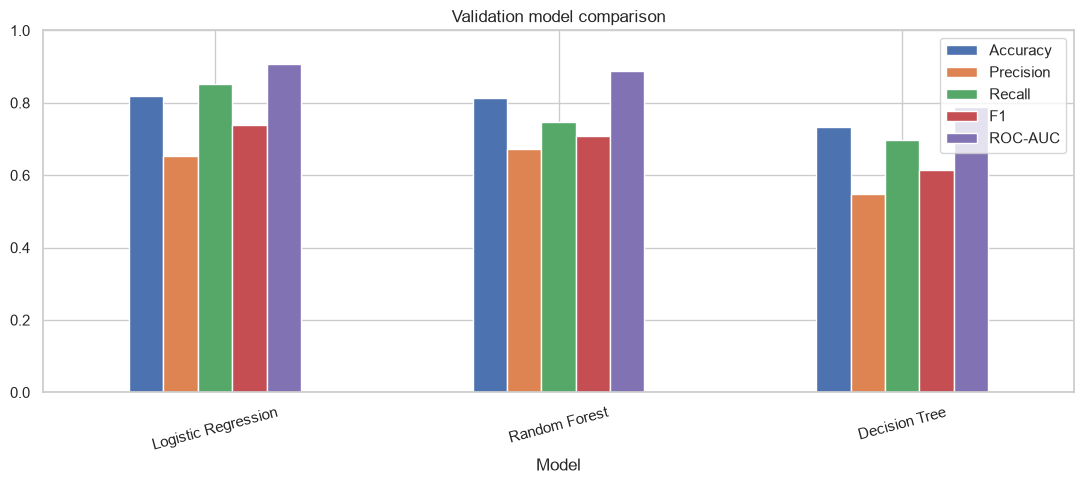

Selected by validation F1: Logistic Regression


In [24]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=250, class_weight="balanced", min_samples_leaf=3,
                                             n_jobs=-1, random_state=RANDOM_STATE)
}
fitted = {}
validation_rows = []
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_val)
    prob = pipe.predict_proba(X_val)[:, 1]
    validation_rows.append({"Model": name,
                            "Accuracy": accuracy_score(y_val, pred),
                            "Precision": precision_score(y_val, pred, zero_division=0),
                            "Recall": recall_score(y_val, pred, zero_division=0),
                            "F1": f1_score(y_val, pred, zero_division=0),
                            "ROC-AUC": roc_auc_score(y_val, prob)})
validation_comparison = pd.DataFrame(validation_rows).set_index("Model").sort_values("F1", ascending=False)
display(validation_comparison.round(4))
validation_comparison.plot(kind="bar", figsize=(11,5), ylim=(0,1), rot=15)
plt.title("Validation model comparison"); plt.tight_layout(); plt.show()
best_name = validation_comparison.index[0]
print("Selected by validation F1:", best_name)

## Exercise 6 — Debunk feature importance / brand double-encoding

In [25]:
# Exercise 6: inspect Brand_5's raw return rate and fitted coefficient sign.
if "brand" in df_clean.columns:
    brand5 = df_clean["brand"].astype("string").str.strip().eq("Brand_5")
    print("Brand_5 order count:", int(brand5.sum()))
    print(
        "Brand_5 actual return rate:",
        round(df_clean.loc[brand5, "returned"].mean(), 4) if brand5.any() else "Brand_5 not found"
    )
    print("Overall return rate:", round(df_clean["returned"].mean(), 4))

best_pipe = fitted[best_name]
model_step = best_pipe.named_steps["model"]
try:
    feature_names = best_pipe.named_steps["preprocessor"].get_feature_names_out()
    if hasattr(model_step, "coef_"):
        signed = pd.Series(model_step.coef_[0], index=feature_names)
        candidates = signed[signed.index.str.contains("Brand_5", case=False, regex=False)]
        print("Brand_5 coefficient(s) in the leakage-audited model:")
        display(candidates.to_frame("signed_coefficient"))
        print(
            "Interpretation: a negative coefficient means lower adjusted log-odds "
            "relative to the reference category, conditional on other features. "
            "It does not establish causation."
        )
    else:
        print("Selected model is tree-based; use tree feature importance, not coefficient sign.")
except Exception as e:
    print("Feature-name inspection unavailable:", e)

print(
    "\nDouble-encoding note: the historical brand_return_rate column is excluded from the "
    "deployment model until verified as point-in-time safe. Do not reintroduce it just to "
    "compare coefficients unless its calculation excludes the current order and future outcomes."
)


Brand_5 order count: 418
Brand_5 actual return rate: 0.0359
Overall return rate: 0.3038
Brand_5 coefficient(s) in the leakage-audited model:


,signed_coefficient
categorical__brand_Brand_5,-2.843602


Interpretation: a negative coefficient means lower adjusted log-odds relative to the reference category, conditional on other features. It does not establish causation.

Double-encoding note: the historical brand_return_rate column is excluded from the deployment model until verified as point-in-time safe. Do not reintroduce it just to compare coefficients unless its calculation excludes the current order and future outcomes.


## Exercise 7 — Leakage-safe model decision

In [26]:
print("Final model inputs:")
print(X.columns.tolist())
print("\nExcluded because of pre-shipment timing or unverified historical leakage:")
print(leakage_drop)
print("\nSupport-related fields removed before the split:")
print(support_related)
print(
    "\nDeployment rule: use only features available at the exact prediction time. "
    "Historical rates require point-in-time construction; never use current-order or future outcomes."
)


Final model inputs:
['product_category', 'sub_category', 'brand', 'discount_percent', 'product_rating', 'review_count', 'fragile_item', 'warranty_available', 'defect_rate', 'seller_rating', 'fulfillment_type', 'payment_method', 'quantity', 'shipping_distance_km', 'wishlist_before_purchase', 'product_page_views', 'log_price']

Excluded because of pre-shipment timing or unverified historical leakage:
['product_return_rate', 'category_return_rate', 'brand_return_rate', 'seller_return_rate', 'delayed_delivery']

Support-related fields removed before the split:
['customer_support_calls', 'chat_interactions']

Deployment rule: use only features available at the exact prediction time. Historical rates require point-in-time construction; never use current-order or future outcomes.


## Exercise 8 — Tune threshold for at least 90% validation recall

Chosen threshold: 0.3974
Validation precision: 0.5955
Validation recall: 0.9039


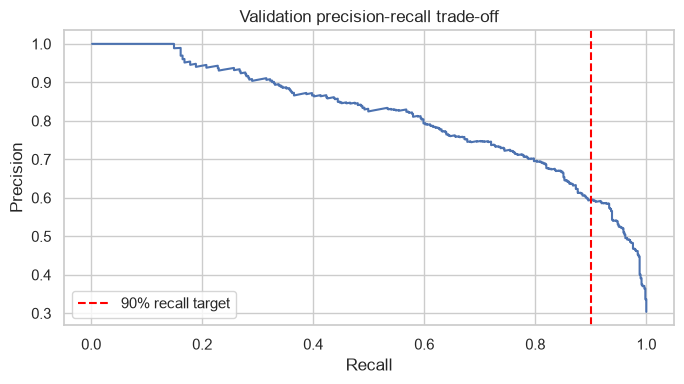

In [27]:
# Choose threshold using validation predictions only. Do not tune on the test set.
val_prob = fitted[best_name].predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_prob)

# precision/recall arrays have one more element than thresholds.
p_vals, r_vals = precision[:-1], recall[:-1]
eligible = np.where(r_vals >= 0.90)[0]

if len(eligible):
    chosen_idx = eligible[np.argmax(p_vals[eligible])]
    chosen_threshold = float(thresholds[chosen_idx])
    print(f"Chosen threshold: {chosen_threshold:.4f}")
    print(f"Validation precision: {p_vals[chosen_idx]:.4f}")
    print(f"Validation recall: {r_vals[chosen_idx]:.4f}")
else:
    # A 0.5 fallback does not guarantee 90% recall; make this explicit.
    chosen_threshold = 0.5
    print("No validation threshold reached 90% recall.")
    print("Using threshold=0.5 as a fallback; report that the target was not achieved.")

plt.figure(figsize=(7, 4))
plt.plot(recall[:-1], precision[:-1])
plt.axvline(0.90, color="red", linestyle="--", label="90% recall target")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation precision-recall trade-off")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Final test evaluation (run once after model/threshold selection)

,Accuracy,Precision,Recall,F1,ROC-AUC
Always not returned,0.6962,0.0000,0.0000,0.0000,NaN
Model threshold=0.5,0.7996,0.6281,0.8340,0.7166,0.8939
Model tuned threshold,0.7688,0.5777,0.8875,0.6998,0.8939


Classification report at tuned threshold:
              precision    recall  f1-score   support

Not returned     0.9359    0.7169    0.8119      1671
    Returned     0.5777    0.8875    0.6998       729

    accuracy                         0.7688      2400
   macro avg     0.7568    0.8022    0.7559      2400
weighted avg     0.8271    0.7688    0.7779      2400



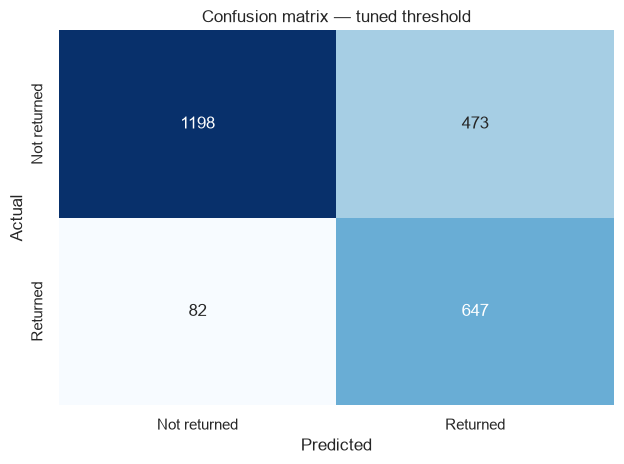


Interpretation: compare threshold=0.5 with the validation-selected threshold. The threshold was chosen on validation data, so test recall may be below 90%. Do not retune using the test labels.


In [28]:
# Final held-out test evaluation. Do not change the threshold after inspecting test results.
final_pipe = fitted[best_name]
test_prob = final_pipe.predict_proba(X_test)[:, 1]
test_pred_05 = (test_prob >= 0.5).astype(int)
test_pred_tuned = (test_prob >= chosen_threshold).astype(int)

def metric_row(y_true, pred, prob=None):
    result = {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
    }
    if prob is not None:
        result["ROC-AUC"] = roc_auc_score(y_true, prob)
    return result

final_results = pd.DataFrame({
    "Always not returned": baseline_metrics,
    "Model threshold=0.5": metric_row(y_test, test_pred_05, test_prob),
    "Model tuned threshold": metric_row(y_test, test_pred_tuned, test_prob),
}).T

display(final_results.round(4))
print("Classification report at tuned threshold:")
print(classification_report(
    y_test, test_pred_tuned,
    target_names=["Not returned", "Returned"],
    digits=4, zero_division=0
))

cm = confusion_matrix(y_test, test_pred_tuned)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Not returned", "Returned"],
    yticklabels=["Not returned", "Returned"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — tuned threshold")
plt.tight_layout()
plt.show()

print(
    "\nInterpretation: compare threshold=0.5 with the validation-selected threshold. "
    "The threshold was chosen on validation data, so test recall may be below 90%. "
    "Do not retune using the test labels."
)


## 10. Feature importance (works with linear and tree models)

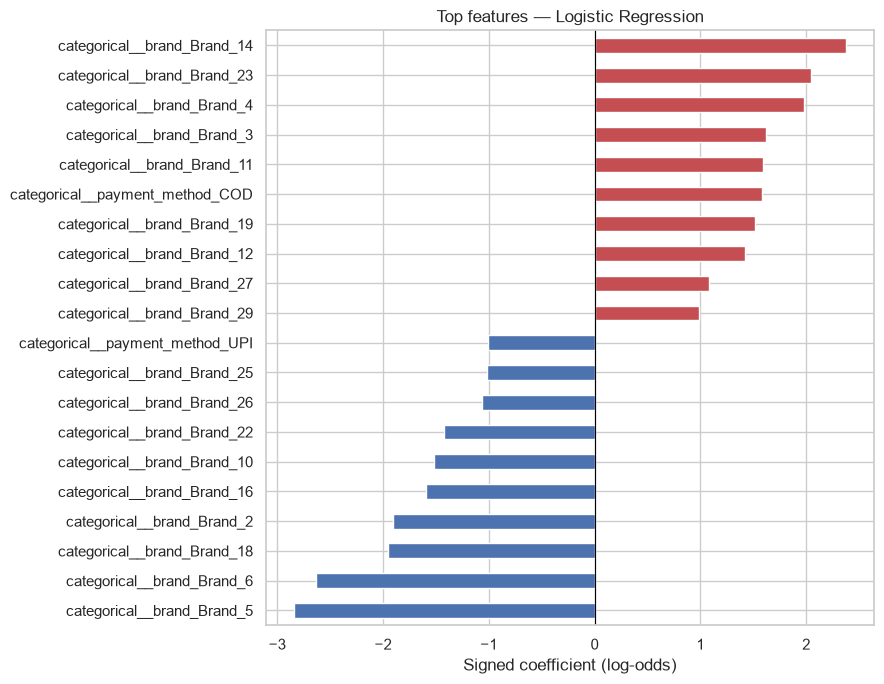

,Signed coefficient (log-odds)
categorical__brand_Brand_5,-2.8436
categorical__brand_Brand_6,-2.6295
categorical__brand_Brand_14,2.3801
categorical__brand_Brand_23,2.0448
categorical__brand_Brand_4,1.9753
categorical__brand_Brand_18,-1.9561
categorical__brand_Brand_2,-1.9099
categorical__brand_Brand_3,1.6230
categorical__brand_Brand_16,-1.5956
categorical__brand_Brand_11,1.5875


In [29]:
try:
    names = final_pipe.named_steps["preprocessor"].get_feature_names_out()
    estimator = final_pipe.named_steps["model"]
    if hasattr(estimator, "coef_"):
        values = estimator.coef_[0]
        importance_label = "Signed coefficient (log-odds)"
        importance = pd.Series(values, index=names).sort_values(key=lambda s: s.abs(), ascending=False).head(20)
        colors = ["#c44e52" if v > 0 else "#4c72b0" for v in importance.values]
        importance.sort_values().plot(kind="barh", figsize=(9,7), color=["#c44e52" if v > 0 else "#4c72b0" for v in importance.sort_values().values])
        plt.axvline(0, color="black", linewidth=.8)
    elif hasattr(estimator, "feature_importances_"):
        importance_label = "Tree feature importance"
        importance = pd.Series(estimator.feature_importances_, index=names).sort_values(ascending=False).head(20)
        importance.sort_values().plot(kind="barh", figsize=(9,7))
    else:
        importance = pd.Series(dtype=float)
        importance_label = "Unavailable"
    plt.title(f"Top features — {best_name}"); plt.xlabel(importance_label); plt.tight_layout(); plt.show()
    display(importance.to_frame(importance_label).round(4))
except Exception as e:
    importance = pd.Series(dtype=float)
    print("Could not calculate feature importance:", e)

## 11. Save model and test loading

In [30]:
# Save the complete pipeline so inference uses identical preprocessing.
model_bundle = {
    "model": final_pipe,
    "model_name": best_name,
    "threshold": chosen_threshold,
    "features": X.columns.tolist(),
    "metrics": final_results.to_dict(orient="index"),
    "target": "returned",
    "prediction_timing": (
        "before shipping; post-purchase fields and unverified historical-rate features excluded"
    ),
}
artifact_path = Path("artifacts/product_return_prediction.joblib")
artifact_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model_bundle, artifact_path)
print("Saved model bundle to:", artifact_path.resolve())

# Reload and verify prediction works with the same feature schema.
loaded = joblib.load(artifact_path)
sample = X_test.head(5)
sample_prob = loaded["model"].predict_proba(sample)[:, 1]
sample_pred = (sample_prob >= loaded["threshold"]).astype(int)
display(pd.DataFrame({
    "return_probability": sample_prob.round(4),
    "predicted_returned": sample_pred,
}, index=sample.index))


Saved model bundle to: D:\Prduct Return Prediction\artifacts\product_return_prediction.joblib


,return_probability,predicted_returned
1650,0.2112,0
5799,0.6557,1
4756,0.8333,1
559,0.2897,0
11982,0.3388,0


## 12. Final report and conclusions

In [31]:
print("=" * 65)
print("PRODUCT RETURN PREDICTION — FINAL REPORT")
print("=" * 65)
print(f"Rows available after cleaning: {len(df_clean):,}")
print(f"Overall return rate: {df_clean['returned'].mean():.2%}")
print(f"Train / validation / test sizes: {len(X_train):,} / {len(X_val):,} / {len(X_test):,}")
print(f"Selected model (validation F1): {best_name}")
print(f"Chosen validation threshold: {chosen_threshold:.4f}")
print("\nFinal held-out test results:")
print(final_results.round(4).to_string())

print("\nInterpretation checklist:")
print("1. Document missing values, category inconsistency, duplicates, and price distribution.")
print("2. Compare three prior guesses with numeric correlations and categorical return rates.")
print("3. Use skewness as evidence; do not automatically log-transform binary features.")
print("4. Explain exact multicollinearity in the support-contact diagnostic.")
print("5. Explain why the constant baseline has zero recall despite high accuracy.")
print("6. Interpret coefficient sign and magnitude carefully; association is not causation.")
print("7. Defend every retained feature based on availability before shipping.")
print("8. Explain the validation-selected threshold and the precision/recall trade-off.")
print("\nReminder: the 90% recall target is selected on validation data; it is not guaranteed on test data.")
print("\nArtifact:", artifact_path.resolve())


PRODUCT RETURN PREDICTION — FINAL REPORT
Rows available after cleaning: 12,000
Overall return rate: 30.38%
Train / validation / test sizes: 7,680 / 1,920 / 2,400
Selected model (validation F1): Logistic Regression
Chosen validation threshold: 0.3974

Final held-out test results:
                       Accuracy  Precision  Recall      F1  ROC-AUC
Always not returned      0.6962     0.0000  0.0000  0.0000      NaN
Model threshold=0.5      0.7996     0.6281  0.8340  0.7166   0.8939
Model tuned threshold    0.7688     0.5777  0.8875  0.6998   0.8939

Interpretation checklist:
1. Document missing values, category inconsistency, duplicates, and price distribution.
2. Compare three prior guesses with numeric correlations and categorical return rates.
3. Use skewness as evidence; do not automatically log-transform binary features.
4. Explain exact multicollinearity in the support-contact diagnostic.
5. Explain why the constant baseline has zero recall despite high accuracy.
6. Interpret coeffi